# Задание 0

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mnist import load_mnist

# Загружаем данные
train, validation, test = load_mnist()

# Извлекаем картинки и метки
X_train_full, y_train_full = train
X_val, y_val = validation
X_test, y_test = test

print(f"Размер обучающей выборки: {X_train_full.shape}")
print(f"Размер валидационной выборки: {X_val.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")

Successfully downloaded train-images-idx3-ubyte.gz 9912422 bytes.
Extracting MNIST-data/train-images-idx3-ubyte.gz
Successfully downloaded train-labels-idx1-ubyte.gz 28881 bytes.
Extracting MNIST-data/train-labels-idx1-ubyte.gz
Successfully downloaded t10k-images-idx3-ubyte.gz 1648877 bytes.
Extracting MNIST-data/t10k-images-idx3-ubyte.gz
Successfully downloaded t10k-labels-idx1-ubyte.gz 4542 bytes.
Extracting MNIST-data/t10k-labels-idx1-ubyte.gz
Размер обучающей выборки: (55000, 28, 28, 1)
Размер валидационной выборки: (5000, 28, 28, 1)
Размер тестовой выборки: (10000, 28, 28, 1)


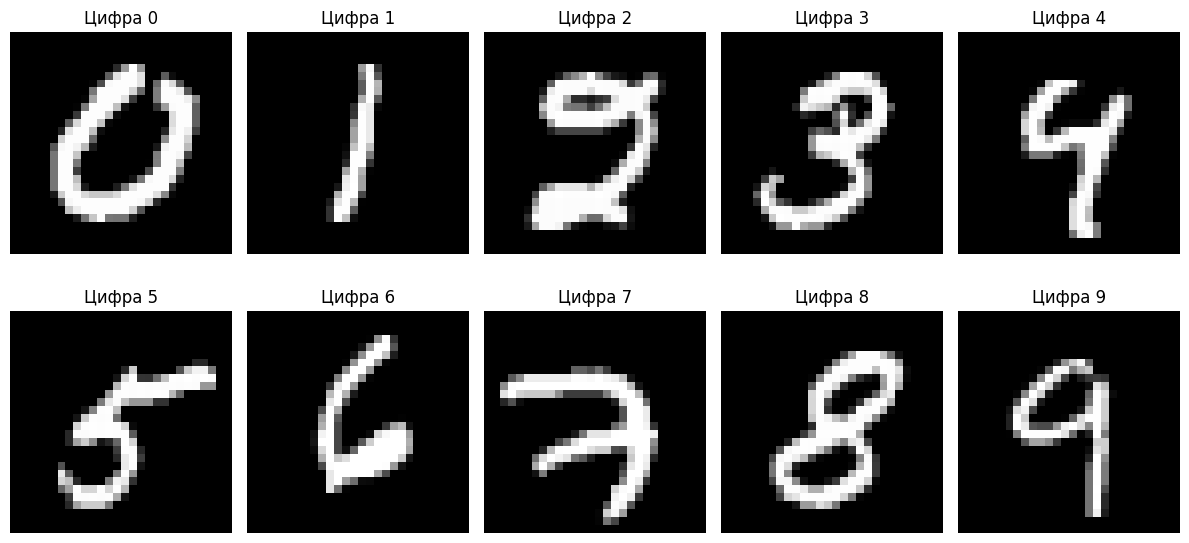

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for digit in range(10):
    i = np.where(y_train_full == digit)[0][0]
    ax = axes[digit // 5, digit % 5]
    ax.imshow(X_train_full[i].reshape(28, 28), cmap='gray')
    ax.set_title(f'Цифра {digit}')
    ax.axis('off')

plt.tight_layout()
plt.show()

In [3]:
# Объединяем train и validation
X = np.concatenate([X_train_full, X_val], axis=0)
y = np.concatenate([y_train_full, y_val], axis=0)

# Преобразуем форму: (n, 28, 28, 1) -> (n, 784)
X = X.reshape(X.shape[0], -1)

# Нормализуем
X = X.astype(np.float32) / 255.0

print(f"Форма X: {X.shape}")
print(f"Форма y: {y.shape}")
print(f"Уникальные классы: {np.unique(y)}")

Форма X: (60000, 784)
Форма y: (60000,)
Уникальные классы: [0 1 2 3 4 5 6 7 8 9]


# Задание 1

In [4]:
class my_PCA:
    def __init__(self, n_components=None):
        """
        Parameters
        ----------
        n_components : int or None
            Количество главных компонент. Если None, сохраняются все.
        """
        self.n_components = n_components
        self.components_ = None       # главные компоненты (собственные векторы)
        self.explained_variance_ = None  # собственные значения
        self.mean_ = None             # среднее по каждому признаку


    def fit(self, X):
        """
        Обучает PCA на данных X.

        Шаги:
        1. Центрировать данные
        2. Вычислить матрицу ковариации (или использовать SVD)
        3. Найти собственные векторы и значения
        4. Отсортировать по убыванию собственных значений
        5. Сохранить первые n_components компонент

        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        """
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_

        U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)

        variance = S**2 / (X.shape[0] - 1)

        self.components_ = Vt[:self.n_components]
        self.explained_variance_ = variance[:self.n_components]

        return self


    def transform(self, X):
        """
        Преобразует данные в координаты главных компонент.

        Y = (X - mean) @ components[:n_components].T

        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)

        Returns
        -------
        Y : np.array, shape (n_samples, n_components)
        """
        return (X - self.mean_) @ self.components_.T


    def fit_transform(self, X):
        """
        Обучает и сразу преобразует.
        """
        return self.fit(X).transform(X)

In [5]:
from sklearn.decomposition import PCA

# Обучаем оба PCA на одних данных
my_pca = my_PCA(n_components=50)
sk_pca = PCA(n_components=50)

Y_my = my_pca.fit_transform(X[:1000])
Y_sk = sk_pca.fit_transform(X[:1000])

# Проверим, что результаты близки (с точностью до знака)
print(f"Сумма собственных значений (my): {my_pca.explained_variance_.sum():.2f}")
print(f"Сумма собственных значений (sklearn): {sk_pca.explained_variance_.sum():.2f}")

print(f"Форма Y_my: {Y_my.shape}")
print(f"Форма Y_sk: {Y_sk.shape}")

Сумма собственных значений (my): 45.48
Сумма собственных значений (sklearn): 45.48
Форма Y_my: (1000, 50)
Форма Y_sk: (1000, 50)


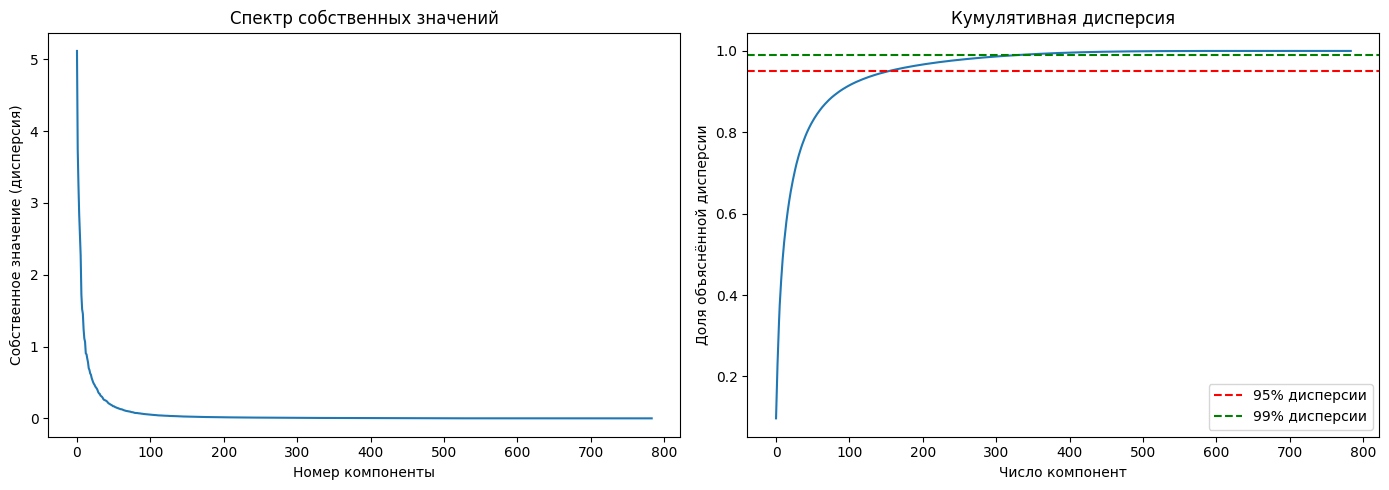

Доля дисперсии первых 15 компонент: 0.5793
Число компонент для 95% дисперсии: 154


In [7]:
pca_full = my_PCA()
pca_full.fit(X)

# Построим графики
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: собственные значения
axes[0].plot(pca_full.explained_variance_)
axes[0].set_xlabel('Номер компоненты')
axes[0].set_ylabel('Собственное значение (дисперсия)')
axes[0].set_title('Спектр собственных значений')

# График 2: кумулятивная дисперсия
cumulative = np.cumsum(pca_full.explained_variance_)
cumulative /= cumulative[-1]

axes[1].plot(cumulative)
axes[1].axhline(y=0.95, color='r', linestyle='--', label='95% дисперсии')
axes[1].axhline(y=0.99, color='g', linestyle='--', label='99% дисперсии')
axes[1].set_xlabel('Число компонент')
axes[1].set_ylabel('Доля объяснённой дисперсии')
axes[1].set_title('Кумулятивная дисперсия')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Доля дисперсии первых 15 компонент: {cumulative[14]:.4f}")
print(f"Число компонент для 95% дисперсии: {np.searchsorted(cumulative, 0.95) + 1}")

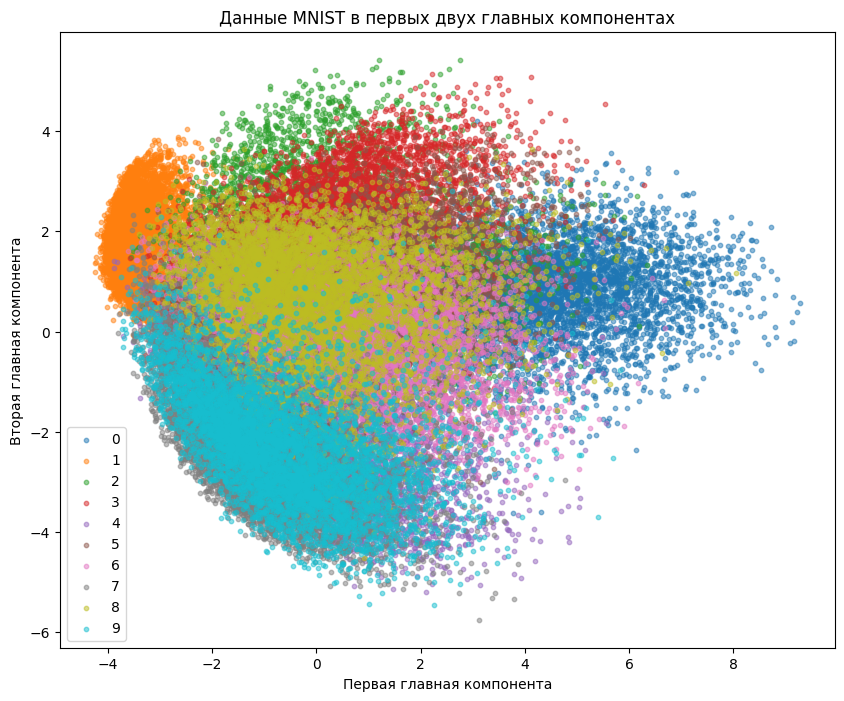

In [8]:
# Преобразуем данные в первые 2 компоненты
pca_2d = my_PCA(n_components=2)
Y_2d = pca_2d.fit_transform(X)

# Построим scatter plot
plt.figure(figsize=(10, 8))

for digit in range(10):
    mask = (y == digit)
    plt.scatter(
        Y_2d[mask, 0],
        Y_2d[mask, 1],
        label=str(digit),
        alpha=0.5,
        s=10
    )

plt.legend()
plt.xlabel('Первая главная компонента')
plt.ylabel('Вторая главная компонента')
plt.title('Данные MNIST в первых двух главных компонентах')
plt.show()

# Задание 2

In [9]:
class my_kNN:
    def __init__(self, n_neighbors=5):
        """
        Parameters
        ----------
        n_neighbors : int
            Число соседей
        """
        self.n_neighbors = n_neighbors
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        """
        Запоминает обучающую выборку.

        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        y : np.array, shape (n_samples,)
        """
        self.X_train = X
        self.y_train = y
        return self

    def predict(self, X):
        """
        Предсказывает классы для объектов X.

        Для каждого объекта x из X:
        1. Вычислите расстояние до всех объектов X_train
        2. Найдите k ближайших
        3. Верните самый частый класс

        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)

        Returns
        -------
        y_pred : np.array, shape (n_samples,)
        """
        predictions = []
        train_sq = np.sum(self.X_train**2, axis=1)

        for i in range(0, len(X), 100):
            batch = X[i:i + 100]

            distances = (
                np.sum(batch**2, axis=1)[:, None]
                + train_sq[None, :]
                - 2 * batch @ self.X_train.T
            )

            nearest = np.argsort(distances, axis=1)[:, :self.n_neighbors]

            for neighbors in nearest:
                labels = self.y_train[neighbors]
                predictions.append(np.bincount(labels, minlength=10).argmax())

        return np.array(predictions)

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Разделим данные
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Обучим свой kNN
my_knn = my_kNN(n_neighbors=5)
my_knn.fit(X_train, y_train)
y_pred_my = my_knn.predict(X_test)

accuracy_my = accuracy_score(y_test, y_pred_my)
print(f"Точность my_kNN: {accuracy_my:.4f}")

Точность my_kNN: 0.9668


In [11]:
from sklearn.neighbors import KNeighborsClassifier

# Обучим sklearn kNN
sk_knn = KNeighborsClassifier(n_neighbors=5)
sk_knn.fit(X_train, y_train)
y_pred_sk = sk_knn.predict(X_test)

accuracy_sk = accuracy_score(y_test, y_pred_sk)
print(f"Точность sklearn kNN: {accuracy_sk:.4f}")
print(f"Разница: {abs(accuracy_my - accuracy_sk):.4f}")

Точность sklearn kNN: 0.9668
Разница: 0.0000


k=1, accuracy=0.9680
k=3, accuracy=0.9690
k=5, accuracy=0.9668
k=7, accuracy=0.9649
k=10, accuracy=0.9628
k=15, accuracy=0.9594
k=20, accuracy=0.9564
k=30, accuracy=0.9519


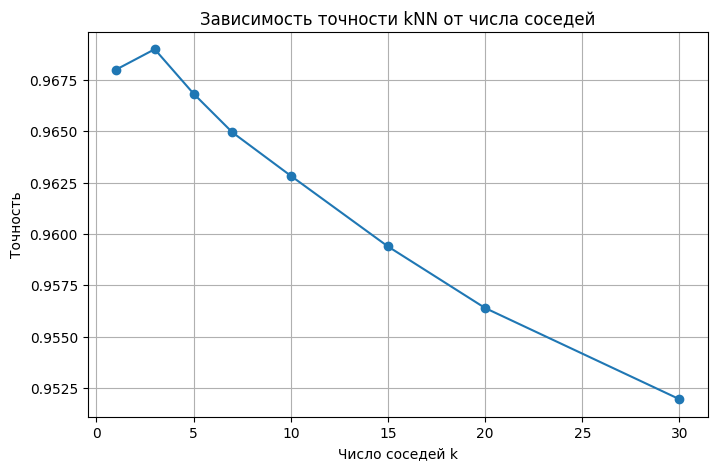

Лучшее k: 3


In [12]:
# Построим график зависимости accuracy от k
k_values = [1, 3, 5, 7, 10, 15, 20, 30]
accuracies = []

for k in k_values:
    knn = my_kNN(n_neighbors=k)
    knn.fit(X_train, y_train)
    pred = knn.predict(X_test)
    acc = accuracy_score(y_test, pred)
    accuracies.append(acc)
    print(f"k={k}, accuracy={acc:.4f}")

# Построим график
plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, 'o-')
plt.xlabel('Число соседей k')
plt.ylabel('Точность')
plt.title('Зависимость точности kNN от числа соседей')
plt.grid(True)
plt.show()

print(f"Лучшее k: {k_values[np.argmax(accuracies)]}")

# Задание 3

Компонент: 1, accuracy: 0.2664
Компонент: 2, accuracy: 0.4119
Компонент: 5, accuracy: 0.7341
Компонент: 10, accuracy: 0.9273
Компонент: 15, accuracy: 0.9581
Компонент: 20, accuracy: 0.9683
Компонент: 30, accuracy: 0.9739
Компонент: 50, accuracy: 0.9743
Компонент: 75, accuracy: 0.9726
Компонент: 100, accuracy: 0.9715
Компонент: 200, accuracy: 0.9683
Компонент: 300, accuracy: 0.9679
Компонент: 500, accuracy: 0.9669
Компонент: 784, accuracy: 0.9668


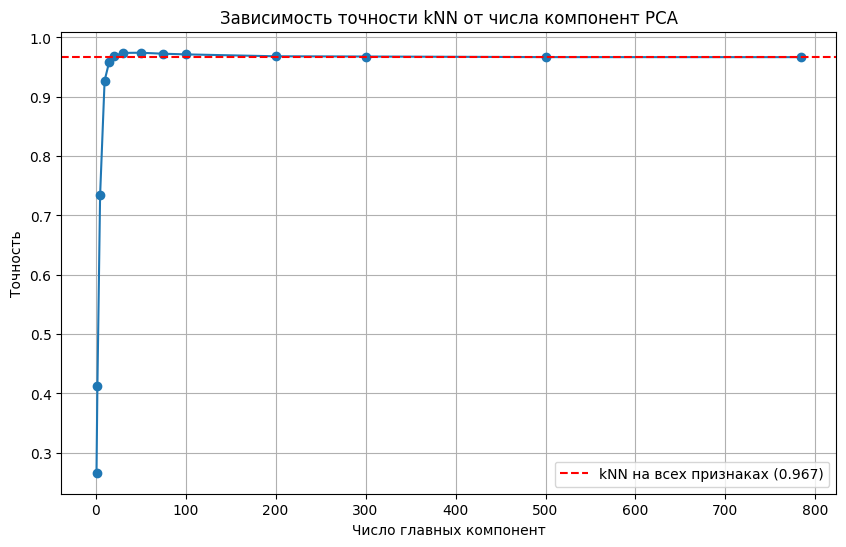

Лучшее число компонент: 50
Лучшая точность: 0.9743
Точность без PCA: 0.9668


In [15]:
pca_train = my_PCA()
pca_train.fit(X_train)

X_train_pca = pca_train.transform(X_train)
X_test_pca = pca_train.transform(X_test)

# Переберем число компонент от 1 до 784
n_components_list = [1, 2, 5, 10, 15, 20, 30, 50, 75, 100, 200, 300, 500, 784]
accuracies_pca = []

for n_comp in n_components_list:
    train_data = X_train_pca[:, :n_comp]
    test_data = X_test_pca[:, :n_comp]

    knn = my_kNN(n_neighbors=5)
    knn.fit(train_data, y_train)

    pred = knn.predict(test_data)
    acc = accuracy_score(y_test, pred)
    accuracies_pca.append(acc)

    print(f"Компонент: {n_comp}, accuracy: {acc:.4f}")

# Построим график
plt.figure(figsize=(10, 6))
plt.plot(n_components_list, accuracies_pca, 'o-')
plt.axhline(
    y=accuracy_my,
    color='r',
    linestyle='--',
    label=f'kNN на всех признаках ({accuracy_my:.3f})'
)
plt.xlabel('Число главных компонент')
plt.ylabel('Точность')
plt.title('Зависимость точности kNN от числа компонент PCA')
plt.legend()
plt.grid(True)
plt.show()

best_i = np.argmax(accuracies_pca)
print(f"Лучшее число компонент: {n_components_list[best_i]}")
print(f"Лучшая точность: {accuracies_pca[best_i]:.4f}")
print(f"Точность без PCA: {accuracy_my:.4f}")

Компонент: 1, время: 23.17 сек
Компонент: 2, время: 27.06 сек
Компонент: 5, время: 27.67 сек
Компонент: 10, время: 27.45 сек
Компонент: 15, время: 27.38 сек
Компонент: 20, время: 28.28 сек
Компонент: 30, время: 28.30 сек
Компонент: 50, время: 29.16 сек
Компонент: 75, время: 28.95 сек
Компонент: 100, время: 30.35 сек
Компонент: 200, время: 32.35 сек
Компонент: 300, время: 34.51 сек
Компонент: 500, время: 38.94 сек
Компонент: 784, время: 45.29 сек


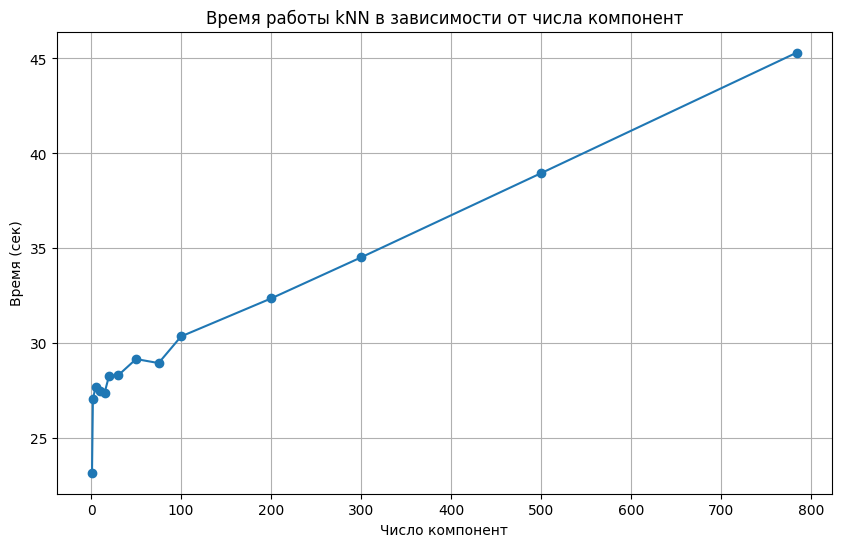

In [16]:
import time

# Замерим время для разных n_components
times = []
for n_comp in n_components_list:
    train_data = X_train_pca[:, :n_comp]
    test_data = X_test_pca[:, :n_comp]

    start = time.time()

    knn = my_kNN(n_neighbors=5)
    knn.fit(train_data, y_train)
    pred = knn.predict(test_data)

    elapsed = time.time() - start
    times.append(elapsed)

    print(f"Компонент: {n_comp}, время: {elapsed:.2f} сек")

# Построим график времени
plt.figure(figsize=(10, 6))
plt.plot(n_components_list, times, 'o-')
plt.xlabel('Число компонент')
plt.ylabel('Время (сек)')
plt.title('Время работы kNN в зависимости от числа компонент')
plt.grid(True)
plt.show()

Компонент: 5, k: 1, accuracy: 0.6902
Компонент: 5, k: 3, accuracy: 0.7192
Компонент: 5, k: 5, accuracy: 0.7341
Компонент: 5, k: 7, accuracy: 0.7393
Компонент: 5, k: 10, accuracy: 0.7457
Компонент: 10, k: 1, accuracy: 0.9154
Компонент: 10, k: 3, accuracy: 0.9252
Компонент: 10, k: 5, accuracy: 0.9273
Компонент: 10, k: 7, accuracy: 0.9262
Компонент: 10, k: 10, accuracy: 0.9265
Компонент: 15, k: 1, accuracy: 0.9533
Компонент: 15, k: 3, accuracy: 0.9570
Компонент: 15, k: 5, accuracy: 0.9581
Компонент: 15, k: 7, accuracy: 0.9572
Компонент: 15, k: 10, accuracy: 0.9555
Компонент: 20, k: 1, accuracy: 0.9661
Компонент: 20, k: 3, accuracy: 0.9689
Компонент: 20, k: 5, accuracy: 0.9683
Компонент: 20, k: 7, accuracy: 0.9678
Компонент: 20, k: 10, accuracy: 0.9654
Компонент: 30, k: 1, accuracy: 0.9742
Компонент: 30, k: 3, accuracy: 0.9745
Компонент: 30, k: 5, accuracy: 0.9739
Компонент: 30, k: 7, accuracy: 0.9725
Компонент: 30, k: 10, accuracy: 0.9704
Компонент: 50, k: 1, accuracy: 0.9728
Компонент: 5

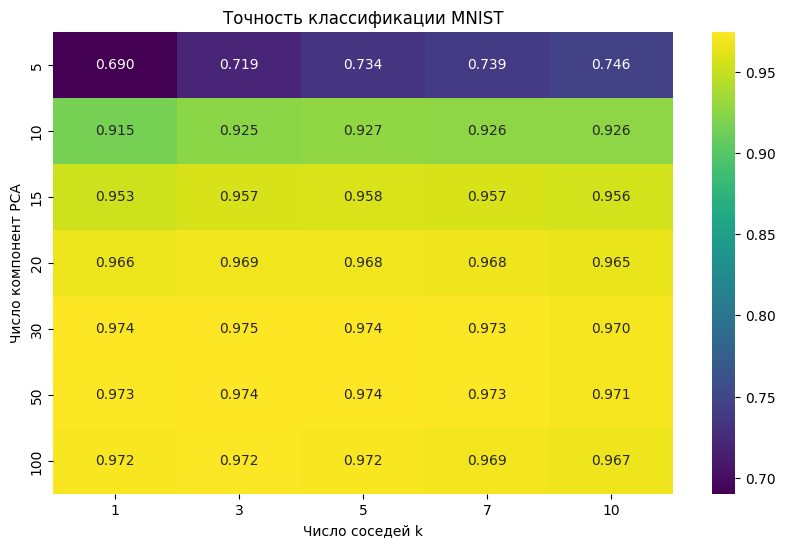

Лучшая комбинация: PCA=30, k=3, accuracy=0.9745
Худшая комбинация: PCA=5, k=1, accuracy=0.6902
Точность без PCA: 0.9668


In [17]:
# Переберем все комбинации
n_components_grid = [5, 10, 15, 20, 30, 50, 100]
k_grid = [1, 3, 5, 7, 10]

accuracy_matrix = np.zeros((len(n_components_grid), len(k_grid)))

for i, n_comp in enumerate(n_components_grid):
    train_data = X_train_pca[:, :n_comp]
    test_data = X_test_pca[:, :n_comp]

    for j, k in enumerate(k_grid):
        knn = my_kNN(n_neighbors=k)
        knn.fit(train_data, y_train)

        pred = knn.predict(test_data)
        accuracy_matrix[i, j] = accuracy_score(y_test, pred)

        print(f"Компонент: {n_comp}, k: {k}, accuracy: {accuracy_matrix[i, j]:.4f}")

# Построим heatmap
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.heatmap(
    accuracy_matrix,
    annot=True,
    fmt='.3f',
    xticklabels=k_grid,
    yticklabels=n_components_grid,
    cmap='viridis'
)
plt.xlabel('Число соседей k')
plt.ylabel('Число компонент PCA')
plt.title('Точность классификации MNIST')
plt.show()

best = np.unravel_index(np.argmax(accuracy_matrix), accuracy_matrix.shape)
worst = np.unravel_index(np.argmin(accuracy_matrix), accuracy_matrix.shape)

print(f"Лучшая комбинация: PCA={n_components_grid[best[0]]}, k={k_grid[best[1]]}, accuracy={accuracy_matrix[best]:.4f}")
print(f"Худшая комбинация: PCA={n_components_grid[worst[0]]}, k={k_grid[worst[1]]}, accuracy={accuracy_matrix[worst]:.4f}")
print(f"Точность без PCA: {accuracy_my:.4f}")

# Выводы

В лабораторной работе были реализованы методы PCA и kNN и проверены на датасете MNIST. PCA уменьшает размерность данных, находя направления с наибольшей дисперсией, что позволяет сохранить основную информацию в меньшем числе признаков. kNN классифицирует объект по наиболее часто встречающемуся классу среди ближайших соседей.

В ходе экспериментов было исследовано, как количество соседей влияет на точность классификации. Также было проверено влияние числа главных компонент на качество и скорость работы kNN. При слишком сильном уменьшении размерности точность снижается из-за потери информации. Оптимальное число компонент следует выбирать по максимальной точности на проверочных данных.